In [1]:
import numpy as np
import torch
from torch import einsum

import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from einops import rearrange
from matplotlib.gridspec import GridSpec

import sys
sys.path.append("/home/rguo_hpc/myfolder/mocap")
from mil.models.timemil import TimeMIL

In [8]:
def exact_cls_attention(trans_layer, x):
    """
    Compute exact (non-Nystrom-approximated) softmax attention from CLS token to all other tokens for a given TransLayer.
    x:       (B, N+1, D) input to this TransLayer (cls token at index 0)
    returns: attn (B, heads, N+1, N+1) full exact attention matrix
    """
    attn_module = trans_layer.attn
    normed = trans_layer.norm(x)          # same pre-norm the layer itself uses
    h = attn_module.heads

    qkv = attn_module.to_qkv(normed)      # (B, N+1, 3*inner_dim)
    q, k, _ = qkv.chunk(3, dim=-1)
    q = rearrange(q, 'b n (h d) -> b h n d', h=h)
    k = rearrange(k, 'b n (h d) -> b h n d', h=h)
    q = q * attn_module.scale

    sim = einsum('b h i d, b h j d -> b h i j', q, k)
    attn = sim.softmax(dim=-1)
    return attn


def frame_importance(model, x, layer='layer1', head_reduction='mean'):
    """
    model:  TimeMIL instance
    x:      raw input (B, L, C)
    layer: 'layer1' or 'layer2' — which TransLayer's CLS attention to use
    """
    with torch.no_grad():
        x = torch.from_numpy(x)
        if model.if_interval:
            x = model.start_conv(x)
        if model.if_extract_feature:
            x = model.feature_extractor(x.transpose(1, 2)).transpose(1, 2)

        B = x.shape[0]
        cls_tokens = model.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = model.pos_layer(x, model.wave1, model.wave2, model.wave3)

        if layer == 'layer1':
            attn = exact_cls_attention(model.layer1, x)
            cls_to_frames = attn[:, :, 0, 1:]          # (B, heads, N_frames)
        else:
            x = model.layer1(x)
            x = model.pos_layer2(x, model.wave1_, model.wave2_, model.wave3_)
            attn = exact_cls_attention(model.layer2, x)
            cls_to_frames = attn[:, :, 0, 1:]

        if head_reduction == 'mean':
            importance = cls_to_frames.mean(dim=1)     # (B, N_frames)
        elif head_reduction == 'max':
            importance = cls_to_frames.max(dim=1).values
        else:
            importance = cls_to_frames                # keep per-head

    return importance.numpy()



def frame_importance_fold(X, model_path = "/home/rguo_hpc/myfolder/mocap/mil/savemodel/InceptBackbone/sdannce/fmr_1/seq_len/3000/best_model.pth", layer = 'layer1'):
    
    milnet = TimeMIL(in_features=192, mDim=192, n_classes=2, dropout=0.25, max_seq_len=3000,
                     if_extract_feature=False, if_interval=True, instance_len=5)
    checkpoint = torch.load(model_path, weights_only=False, map_location="cpu")
    milnet.load_state_dict(checkpoint)

    imp = frame_importance(milnet, X, layer, 'mean')
    return imp

In [9]:
X = np.load("/home/rguo_hpc/myfolder/mocap/outputs/sdannce/fmr1/50/representations/mae_sdannce_val.npy")[:, 25:3025]#[:;2, ::2]
X.shape

(180, 3000, 192)

In [10]:
l1 = frame_importance_fold(X = X, layer = 'layer1')
l2 = frame_importance_fold( X = X, layer = 'layer2')
scores = (l1 + l2)/2

In [11]:
def plot_importance_heatmap(importance, title="Frame Importance", xlabel="Frame index", ylabel="Sequence", normalize="row"):
    """
    normalize: None | "row" (per-sequence min-max, best for spotting relative peaks)| "global" (min-max across whole array)
    clip_percentile: clip top/bottom p% before scaling color, to kill outlier dominance
    """
    n, L = importance.shape
    imp = importance.copy()

    if normalize == "row":
        row_min = imp.min(axis=1, keepdims=True)
        row_max = imp.max(axis=1, keepdims=True)
        imp = (imp - row_min) / (row_max - row_min + 1e-8)
    elif normalize == "global":
        imp = (imp - imp.min()) / (imp.max() - imp.min() + 1e-8)

    figsize = (min(0.15 * L, 15), min(0.25 * n, 9))
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(imp, aspect="auto", cmap="viridis", interpolation="nearest")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label="Importance (normalized)")
    plt.tight_layout()
    return imp,fig, ax

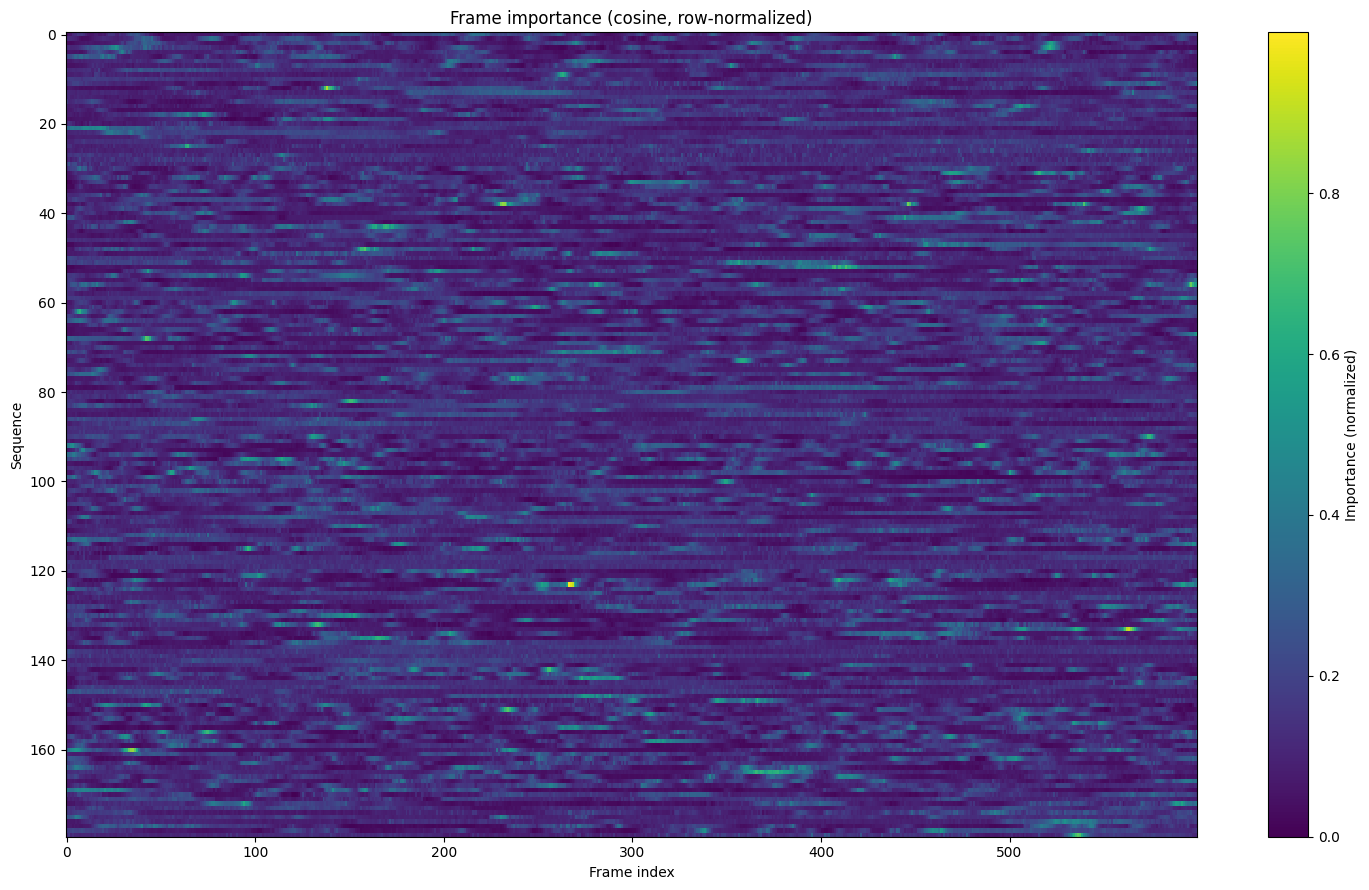

In [27]:
imp, fig, ax = plot_importance_heatmap(scores, title="Frame importance (cosine, row-normalized)", normalize="global")
plt.show()

In [19]:
L = 3000 
tp = 5
l = int(L/tp) # after patch
N = int(90000/3000)
D = 192
fmr1_fold_1 = {"train":[402, 404, 405, 406, 407, 408], "valid": [401, 403]}
#sample_frequency = 5

In [20]:
import pickle
from scipy.stats import mode

In [21]:
# load original data 
with open("/home/rguo_hpc/myfolder/data/sdannce/data_fmr1.pkl", 'rb') as file:
    result = pickle.load(file)

for mouse in fmr1_fold_1["valid"]:     # result.keys(): [408, 407, 404, 403, 402, 406, 405, 401]
    num_seq = len(result[mouse]["ratid"])
    ratgen  = int(result[mouse]["ratgen"])
    result[mouse]["ratgen"] = [ratgen for i in range(num_seq * N,)]
    ratid = result[mouse]["ratid"][0]
    result[mouse]["ratid"] = [ratid for i in range(num_seq * N,)]
    
    # llac    
    llac = np.array(result[mouse]["llac"])
    llac = llac.reshape(-1, L,)
    if tp > 1:
        grouped_llac = llac.reshape(-1, l, tp) # choose the mode label of each patch 
        result[mouse]["llac"] = mode(grouped_llac, axis=2, keepdims=False).mode.astype(np.uint8)
    else:
        result[mouse]["llac"] = llac
    
    # hlac
    hlac = np.array(result[mouse]["hlac"]) # (3, 90000, 1)
    hlac = hlac.reshape(-1, L,)
    if tp > 1:
        grouped_hlac = hlac.reshape(-1, l, tp)
        result[mouse]["hlac"] = mode(grouped_hlac, axis=2, keepdims=False).mode.astype(np.uint8)
    else:
        result[mouse]["hlac"] = hlac
    
    del result[mouse]["m1"]

In [22]:
hlac_val, llac_val = [], []
ratgen = []

for mouse_id in fmr1_fold_1["valid"]:
    hlac_val.append(result[mouse_id]["hlac"])
    llac_val.append(result[mouse_id]["llac"]) 
    ratgen.append(result[mouse]["ratgen"])

hlac_val = np.concatenate(hlac_val)#[:,::sample_frequency]
llac_val = np.concatenate(llac_val)#[:,::sample_frequency]
ratgen = np.concatenate(ratgen)

In [26]:
selected_labels = hlac_val[imp > 0.9]
unique, counts = np.unique(selected_labels, return_counts=True)
distribution = dict(zip(unique, counts))
print(distribution)

attention_mask = np.where(imp > 0.95, 1, 0)
hlac_mask = attention_mask * hlac_val

{1: 92, 2: 234, 3: 1, 5: 8, 7: 203, 8: 69}


In [28]:
correct_indices = [1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
 20, 21, 22, 23, 26, 29, 30, 33, 34, 35, 36, 37, 38, 39, 40, 42, 44,
 46, 47, 48, 49, 50, 51, 52, 56, 57, 59, 60, 61, 63, 65, 66, 67, 70,
 71, 73, 74, 75, 76, 77, 78, 79, 80, 81, 83, 84, 86, 88]

In [ ]:
Test labels: 
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0], 
 
Test predictions: 
[0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0 1 1 0 0 1 1 1 1
 1 1 1 1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 0 0 0 1 1 0 0 1
 0 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0]
Confusion Matrix:
[[32 13]
 [10 35]]